# Discrete Mathematics: Automata and Regular Languages

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising *Theory of Automata / Theory of Computation* (a core course in HEC-style BS CS and BS AI programmes) for an exam or interview.
>
> **What you will learn**
> - Alphabets, strings and **languages**, and why they matter for tokenizers, lexers, input validators and LLM output constraints
> - **Deterministic finite automata (DFA)** as a small Python class: simulate, trace and draw them
> - **Nondeterministic** automata (NFA and ε-NFA) and the **subset construction** that turns an NFA into a DFA (with its exponential worst case)
> - **Regular expressions** and **Thompson's construction**: a working mini regex engine (concatenation, `|`, `*`, `+`, `?`, character classes), tested against Python's `re`
> - **DFA minimisation** with the table-filling algorithm, and deciding whether two regexes are equivalent
> - **Closure properties** (union, intersection, complement) with the product construction
> - The **pumping lemma** (and Myhill–Nerode) to prove that $a^nb^n$ and balanced parentheses are **not** regular
> - **Catastrophic backtracking (ReDoS)** in real regex engines, measured, and how to avoid it
> - **Mealy and Moore machines**, and a chatbot conversation flow as a finite-state machine
> - **Constrained decoding**: forcing a (toy) language model to emit output that matches a regex, the idea behind JSON-mode and structured-output libraries
>
> **Prerequisites:** [`01_sets_relations_functions_and_proofs.ipynb`](01_sets_relations_functions_and_proofs.ipynb) (sets, functions, proofs, closure) and [`03_graph_theory.ipynb`](03_graph_theory.ipynb) (directed graphs). Helpful: basic regex use, as in [`07_NLP/01_text_preprocessing.ipynb`](../../07_NLP/01_text_preprocessing.ipynb).
>
> **Time needed:** about 3 to 4 hours.
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library (including `re`), numpy, pandas, matplotlib, networkx. The notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Sipser, *Introduction to the Theory of Computation* (3rd ed.), chapter 1, and Hopcroft, Motwani and Ullman, *Introduction to Automata Theory, Languages, and Computation* (3rd ed.), chapters 2–4.

## Explained simply

A **finite automaton** is a machine with a small, fixed number of "moods" (called **states**) that reads text one character at a time and changes mood depending on what it reads. When the text ends, the machine either accepts it ("yes, this looks right") or rejects it. It has no memory except its current state, so it cannot count arbitrarily high. Despite that, these simple machines power every search box, every spam filter rule, every programming-language tokenizer, and the regular expressions (regex) programmers use daily. Learning how they work tells you what a regex *can* check (like "is this a valid date format?") and what it can never check (like "are these brackets balanced?").

**Everyday examples.**
- A **turnstile** at a metro station has two states, *locked* and *unlocked*. Inserting a coin moves it to unlocked; pushing through moves it back to locked. That is a finite-state machine.
- A **traffic light** cycles through green, yellow and red; a **vending machine** remembers how much money you have put in so far (up to the price) and gives a snack at the right moment.
- When a website rejects your email address as "invalid format" the instant you type it, a regular expression (secretly a finite automaton) has just read your input.

**A tiny example.** A machine checks whether a binary number is even. It has two states: *last digit was 0* (accepting) and *last digit was 1*. Read `1`, `0`, `1`, `0` (the number 10): the states go 1 → 0 → 1 → 0, and it ends in the "last digit was 0" state, so it accepts: 10 is even. For `111` (the number 7) it ends in the "last digit was 1" state and rejects.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Finite automaton (DFA / NFA) | a machine with a few states that reads input one symbol at a time | turnstiles, vending machines, tokenizers and lexers |
| Regular expression | a compact pattern describing which strings are allowed | form validation, log searching, data cleaning, JSON-mode for LLMs |
| Non-regular language | a pattern that needs unlimited memory (like matching brackets) | why regex cannot parse HTML or nested JSON, and parsers are needed |

### How this notebook relates to others
Regexes are *used* in about two dozen notebooks of this repo (text cleaning, log parsing, validation). This notebook explains the theory behind them. The next notebook, [`05_grammars_parsing_and_computability.ipynb`](05_grammars_parsing_and_computability.ipynb), climbs the Chomsky hierarchy: context-free grammars, pushdown automata, Turing machines and the limits of computation.

## Table of contents
1. Alphabets, strings and languages
2. Deterministic finite automata (DFA)
3. Nondeterministic finite automata (NFA and ε-NFA)
4. The subset construction: NFA → DFA
5. Regular expressions and Thompson's construction
6. DFA minimisation and regex equivalence
7. Closure properties and decision problems
8. Proving a language is not regular
9. Regex in production: catastrophic backtracking (ReDoS)
10. Mealy and Moore machines
11. Summary table
12. How this connects to modern AI: constrained decoding
13. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import re
from itertools import product
from collections import deque, defaultdict
import networkx as nx

def strings_up_to(alphabet, n):
    """All strings over `alphabet` of length 0..n, shortest first (the start of Σ* in order)."""
    out = []
    for k in range(n + 1):
        out += ["".join(p) for p in product(sorted(alphabet), repeat=k)]
    return out

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Alphabets, strings and languages

> **In plain English:** a language is just a set of allowed strings, like the set of valid email addresses.

**Definitions.**
- An **alphabet** Σ is a finite, non-empty set of symbols: {0, 1}, {a, b}, the 26 letters, the bytes 0–255, or an LLM's token vocabulary.
- A **string** (word) over Σ is a finite sequence of symbols. |w| is its length. The **empty string** ε has length 0.
- **Σ\*** is the set of *all* strings over Σ (including ε); Σ⁺ = Σ\* without ε. Σ\* is infinite but countable (list strings by length, then alphabetically).
- A **language** is any set of strings, $L \subseteq \Sigma^*$.

**Operations on strings:** concatenation $xy$, powers $w^k$ ($w^0 = \varepsilon$), reversal $w^R$.

**Operations on languages:** besides ∪, ∩ and complement (languages are sets), the regular operations are
- **concatenation** $L_1 L_2 = \{xy \mid x \in L_1, y \in L_2\}$,
- **Kleene star** $L^* = \{\varepsilon\} \cup L \cup LL \cup LLL \cup \dots$ (zero or more pieces from L glued together).

> ⚠️ **Common mistake:** ∅ (the empty *language*, no strings at all) is not {ε} (a language with one string, the empty one). $L\varnothing = \varnothing$ but $L\{\varepsilon\} = L$. And $\varnothing^* = \{\varepsilon\}$.

In [2]:
def concat(L1, L2):
    return {x + y for x in L1 for y in L2}

def star(L, max_len):
    """Kleene star, cut off at strings of length <= max_len (L* itself is infinite)."""
    result, frontier = {""}, {""}
    while frontier:
        frontier = {x + y for x in frontier for y in L if len(x + y) <= max_len} - result
        result |= frontier
    return result

L1, L2 = {"a", "ab"}, {"b", ""}
print("L1 L2       =", sorted(concat(L1, L2)))
print("L1 ∅        =", concat(L1, set()), "   L1 {ε} =", sorted(concat(L1, {""})))
print("{ab}* (≤ 6) =", sorted(star({"ab"}, 6), key=len))
print("{a, ab}* up to length 4:", sorted(star({"a", "ab"}, 4), key=lambda s: (len(s), s)))
print("Σ* for Σ = {0,1}, length ≤ 3:", strings_up_to("01", 3))

L1 L2       = ['a', 'ab', 'abb']
L1 ∅        = set()    L1 {ε} = ['a', 'ab']
{ab}* (≤ 6) = ['', 'ab', 'abab', 'ababab']
{a, ab}* up to length 4: ['', 'a', 'aa', 'ab', 'aaa', 'aab', 'aba', 'aaaa', 'aaab', 'aaba', 'abaa', 'abab']
Σ* for Σ = {0,1}, length ≤ 3: ['', '0', '1', '00', '01', '10', '11', '000', '001', '010', '011', '100', '101', '110', '111']


**Why this matters for AI.** A tokenizer splits text into strings over a vocabulary; a JSON schema defines a language of valid outputs; an input validator accepts a language of safe inputs. The question "*which kinds of languages can a simple machine recognise?*" decides which of these checks are cheap and which need more powerful tools.

---
## 2. Deterministic finite automata (DFA)

> **In plain English:** a DFA is a machine with a few states that reads one character at a time and ends in 'yes' or 'no'.

**Definition.** A **DFA** is a 5-tuple $M = (Q, \Sigma, \delta, q_0, F)$:
- Q: a finite set of **states**;
- Σ: the input alphabet;
- $\delta: Q \times \Sigma \to Q$: the **transition function** (exactly one next state for each state and symbol, hence "deterministic");
- $q_0 \in Q$: the **start state**;
- $F \subseteq Q$: the **accepting** (final) states.

M reads w one symbol at a time starting in $q_0$; it **accepts** w if it ends in a state of F. The **language** of M is $L(M) = \{w \mid M \text{ accepts } w\}$. A language is **regular** if some DFA recognises it.

**Worked example: binary numbers divisible by 3.** Track the remainder r of the number read so far. Reading bit b turns the number x into 2x + b, so the remainder becomes (2r + b) mod 3:

| state (remainder) | read 0 | read 1 |
|---|---|---|
| → **r0** (accepting) | r0 | r1 |
| r1 | r2 | r0 |
| r2 | r1 | r2 |

Trace of `110` (= 6): r0 →1→ r1 →1→ r0 →0→ r0. Ends in r0: accept.

In code, δ is a dictionary from (state, symbol) to state. If a pair is missing we treat it as going to an implicit **dead state** (a rejecting trap), which keeps diagrams small.

,0,1
→ r0 *,r0,r1
r1,r2,r0
r2,r1,r2


trace of 110: r0 → r1 → r0 → r0 | accepted: True


verified on all 8,190 binary strings of length 1..12


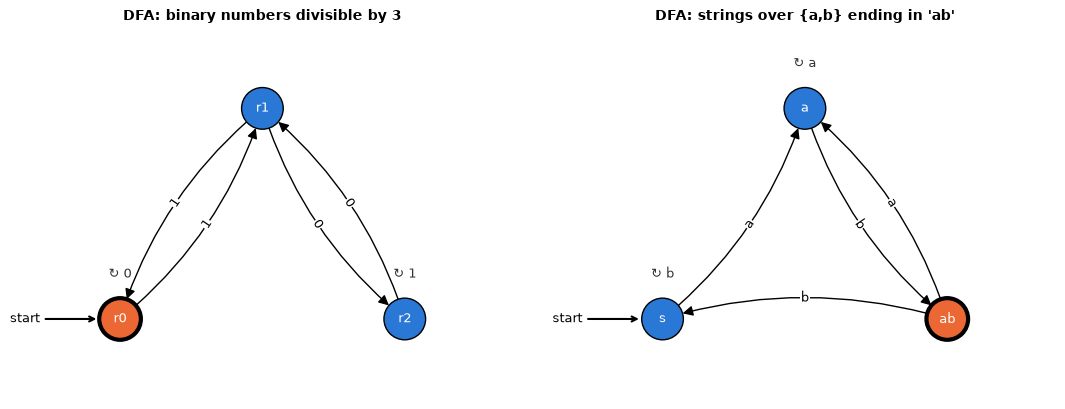

In [3]:
class DFA:
    def __init__(self, states, alphabet, delta, start, accept):
        self.states = list(states)
        self.alphabet = sorted(alphabet)
        self.delta = dict(delta)            # (state, symbol) -> state; missing = dead state
        self.start = start
        self.accept = set(accept)

    def run(self, w):
        """Return the list of states visited (None means we fell into the dead state)."""
        q, visited = self.start, [self.start]
        for ch in w:
            q = self.delta.get((q, ch))
            visited.append(q)
            if q is None:
                break
        return visited

    def accepts(self, w):
        return self.run(w)[-1] in self.accept

    def table(self):
        rows = {}
        for q in self.states:
            label = ("→ " if q == self.start else "") + str(q) + (" *" if q in self.accept else "")
            rows[label] = {a: self.delta.get((q, a), "∅") for a in self.alphabet}
        return pd.DataFrame(rows).T

def draw_automaton(states, transitions, start, accept, ax, title, pos=None, node_size=900, font_size=9):
    """Draw an automaton. transitions: dict (p, q) -> list of labels. Accepting states are orange with a
    thick ring; a self-loop is shown as '↻ label' above its state."""
    G = nx.DiGraph()
    G.add_nodes_from(states)
    labels, loops = {}, {}
    for (p, q), syms in transitions.items():
        lab = ",".join(sorted(syms))
        if p == q:
            loops[p] = lab                       # drawn as text, which stays readable
        else:
            G.add_edge(p, q)
            labels[(p, q)] = lab
    pos = pos or nx.circular_layout(G)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[PALETTE[1] if s in accept else PALETTE[0] for s in G],
                           node_size=node_size, edgecolors="black", linewidths=[3 if s in accept else 1 for s in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_color="white", font_size=font_size)
    nx.draw_networkx_edges(G, pos, ax=ax, connectionstyle="arc3,rad=0.15", arrows=True, arrowsize=15,
                           node_size=node_size)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, ax=ax, connectionstyle="arc3,rad=0.15",
                                 font_size=9, bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    lift = 14 + node_size ** 0.5 / 2.2           # points above the node centre
    for q, lab in loops.items():
        ax.annotate(f"↻ {lab}", xy=pos[q], xytext=(0, lift), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color="#333333")
    ax.annotate("start", xy=pos[start], xytext=(-lift - 30, 0), textcoords="offset points", va="center", ha="right",
                fontsize=9, arrowprops=dict(arrowstyle="->", lw=1.5, shrinkB=node_size ** 0.5 / 2 + 2))
    ax.set_title(title, fontsize=10); ax.axis("off"); ax.margins(0.3)

def dfa_transitions(dfa):
    tr = defaultdict(list)
    for (p, a), q in dfa.delta.items():
        tr[(p, q)].append(a)
    return tr

div3 = DFA(["r0", "r1", "r2"], "01",
           {("r0", "0"): "r0", ("r0", "1"): "r1", ("r1", "0"): "r2",
            ("r1", "1"): "r0", ("r2", "0"): "r1", ("r2", "1"): "r2"}, "r0", {"r0"})
display(div3.table())
print("trace of 110:", " → ".join(div3.run("110")), "| accepted:", div3.accepts("110"))
for w in strings_up_to("01", 12)[1:]:                         # every non-empty string up to length 12
    assert div3.accepts(w) == (int(w, 2) % 3 == 0)
print("verified on all 8,190 binary strings of length 1..12")

ends_ab = DFA(["s", "a", "ab"], "ab",
              {("s", "a"): "a", ("s", "b"): "s", ("a", "a"): "a", ("a", "b"): "ab",
               ("ab", "a"): "a", ("ab", "b"): "s"}, "s", {"ab"})
assert all(ends_ab.accepts(w) == w.endswith("ab") for w in strings_up_to("ab", 10))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
draw_automaton(div3.states, dfa_transitions(div3), "r0", div3.accept, axes[0],
               "DFA: binary numbers divisible by 3", pos={"r0": (0, 0), "r1": (1, 0.6), "r2": (2, 0)})
draw_automaton(ends_ab.states, dfa_transitions(ends_ab), "s", ends_ab.accept, axes[1],
               "DFA: strings over {a,b} ending in 'ab'", pos={"s": (0, 0), "a": (1, 0.6), "ab": (2, 0)})
plt.tight_layout(); plt.show()

**What just happened?** The 3-state machine agrees with `int(w, 2) % 3 == 0` on every binary string up to length 12, even though it never stores the number: the remainder is all it needs to remember. Accepting states are drawn orange with a thick ring.

**Complexity.** Running a DFA on a string of length n takes **Θ(n) time and O(1) extra memory**: one dictionary lookup per symbol. This is why DFAs are used for high-speed matching (network intrusion detection, lexers, `grep`).

> 🎓 **Exam / interview tip:** to design a DFA, first decide **what the machine must remember** about the prefix read so far (a remainder, the last two symbols, a parity). Each possible "memory value" becomes a state. If the memory would need to grow without bound (a count of a's to compare with b's), the language is probably not regular (Section 8).

---
## 3. Nondeterministic finite automata (NFA and ε-NFA)

> **In plain English:** an NFA is allowed to guess, and accepts if any sequence of guesses works.

**Intuition.** An NFA may have **several** possible moves (or none) on a symbol, and may also jump along **ε-transitions** without reading anything. It accepts if **some** sequence of choices ends in an accepting state. Think of it as exploring all choices in parallel, or as a machine that always "guesses right".

**Definition.** An **ε-NFA** is $N = (Q, \Sigma, \delta, q_0, F)$ with $\delta: Q \times (\Sigma \cup \{\varepsilon\}) \to \mathcal{P}(Q)$ (a *set* of next states, possibly empty).

**Simulation.** Keep the set S of all states the NFA could be in. The **ε-closure** E(S) adds every state reachable from S by ε-moves alone. Start with $E(\{q_0\})$; on symbol a, move to $E(\bigcup_{q \in S}\delta(q, a))$; accept if the final set contains an accepting state.

**Example: "the 3rd symbol from the end is 1".** The NFA reads anything, *guesses* when it has reached the third-last symbol, checks it is a 1, then reads exactly two more symbols:

```
      0,1
     ┌───┐
     ▼   │      1          0,1          0,1
──► (q0)─┴──────────► (q1) ───────► (q2) ───────► ((q3))
```
4 states. A DFA must remember the last three symbols, which needs $2^3 = 8$ states (Section 4 proves it).

In [4]:
EPS = ""                                        # we use the empty string as the ε label

class NFA:
    def __init__(self, states, alphabet, delta, start, accept):
        self.states = set(states)
        self.alphabet = sorted(alphabet)
        self.delta = defaultdict(set)           # (state, symbol or EPS) -> set of states
        for key, targets in delta.items():
            self.delta[key] |= set(targets)
        self.start = start
        self.accept = set(accept)

    def eps_closure(self, S):
        """All states reachable from S using only ε-moves (DFS)."""
        stack, closure = list(S), set(S)
        while stack:
            q = stack.pop()
            for r in self.delta.get((q, EPS), ()):
                if r not in closure:
                    closure.add(r); stack.append(r)
        return frozenset(closure)

    def step(self, S, a):
        return self.eps_closure({r for q in S for r in self.delta.get((q, a), ())})

    def accepts(self, w):
        S = self.eps_closure({self.start})
        for ch in w:
            S = self.step(S, ch)
            if not S:
                return False                    # every branch died
        return bool(S & self.accept)

def nth_from_last_is_1(n):
    """NFA with n + 1 states: guess the position of the n-th symbol from the end."""
    delta = {(0, "0"): {0}, (0, "1"): {0, 1}}
    for i in range(1, n):
        delta[(i, "0")] = {i + 1}; delta[(i, "1")] = {i + 1}
    return NFA(range(n + 1), "01", delta, 0, {n})

N3 = nth_from_last_is_1(3)
for w in strings_up_to("01", 12):
    assert N3.accepts(w) == (len(w) >= 3 and w[-3] == "1")
print("NFA for '3rd from last is 1' verified on all strings up to length 12")

S = N3.eps_closure({0})
trace = [("start", sorted(S))]
for ch in "0110":
    S = N3.step(S, ch)
    trace.append((ch, sorted(S)))
print("set of possible states while reading 0110:", trace, "-> accept" if S & N3.accept else "-> reject")

NFA for '3rd from last is 1' verified on all strings up to length 12
set of possible states while reading 0110: [('start', [0]), ('0', [0]), ('1', [0, 1]), ('1', [0, 1, 2]), ('0', [0, 2, 3])] -> accept


**What just happened?** While reading `0110`, the set of "possible current states" grows whenever a 1 is read (the NFA might be at the third-last symbol) and shifts along. After the last symbol it contains state 3 because the third-last symbol of `0110` is 1.

**Complexity of simulating an NFA.** Each step updates a set of at most |Q| states, each with its transitions: **O(n · |Q|²)** in the worst case for a string of length n (O(n · |δ|) with adjacency lists). Still linear in the input length, with no exponential blow-up, which is the key fact behind safe regex engines (Section 9).

---
## 4. The subset construction: NFA → DFA

> **In plain English:** any guessing machine can be turned into a non-guessing one by tracking every possible guess at once, though it may get much bigger.

**Theorem (Rabin and Scott, 1959).** Every NFA (with or without ε-moves) has an equivalent DFA. So NFAs recognise exactly the regular languages: nondeterminism adds convenience, not power.

**Construction.** The DFA's states are **sets of NFA states**: exactly the sets S that the simulation in Section 3 passes through.
- start state: $E(\{q_0\})$;
- $\delta_D(S, a) = E\big(\bigcup_{q \in S} \delta_N(q, a)\big)$;
- S is accepting iff it contains an accepting NFA state.

There are up to $2^{|Q|}$ subsets, but we build only those **reachable** from the start (a BFS over subsets), which in practice is usually far fewer.

In [5]:
def subset_construction(nfa):
    """NFA -> DFA whose states are frozensets of NFA states (only the reachable ones)."""
    start = nfa.eps_closure({nfa.start})
    delta, seen, queue = {}, {start}, deque([start])
    while queue:
        S = queue.popleft()
        for a in nfa.alphabet:
            T = nfa.step(S, a)
            if not T:
                continue                                  # empty set = dead state, left implicit
            delta[(S, a)] = T
            if T not in seen:
                seen.add(T); queue.append(T)
    accept = {S for S in seen if S & nfa.accept}
    return DFA(list(seen), nfa.alphabet, delta, start, accept)

def relabel(dfa, prefix="D"):
    """Rename states to D0, D1, ... in BFS order from the start (for readable tables)."""
    order, queue = [dfa.start], deque([dfa.start])
    while queue:
        q = queue.popleft()
        for a in dfa.alphabet:
            r = dfa.delta.get((q, a))
            if r is not None and r not in order:
                order.append(r); queue.append(r)
    name = {q: f"{prefix}{i}" for i, q in enumerate(order)}
    return DFA([name[q] for q in order], dfa.alphabet,
               {(name[p], a): name[q] for (p, a), q in dfa.delta.items() if p in name},
               name[dfa.start], {name[q] for q in dfa.accept if q in name}), name

D3 = subset_construction(N3)
D3r, names = relabel(D3)
print(f"NFA with {len(N3.states)} states -> DFA with {len(D3.states)} states")
print("which NFA states each DFA state stands for:", {v: sorted(k) for k, v in names.items()})
display(D3r.table())
for w in strings_up_to("01", 12):
    assert D3.accepts(w) == N3.accepts(w)
print("DFA and NFA agree on all strings up to length 12")

NFA with 4 states -> DFA with 8 states
which NFA states each DFA state stands for: {'D0': [0], 'D1': [0, 1], 'D2': [0, 2], 'D3': [0, 1, 2], 'D4': [0, 3], 'D5': [0, 1, 3], 'D6': [0, 2, 3], 'D7': [0, 1, 2, 3]}


,0,1
→ D0,D0,D1
D1,D2,D3
D2,D4,D5
D3,D6,D7
D4 *,D0,D1
D5 *,D2,D3
D6 *,D4,D5
D7 *,D6,D7


DFA and NFA agree on all strings up to length 12


**What just happened?** The 4-state NFA became an 8-state DFA. Each DFA state is a set like {0, 1, 3}, which in plain words says "the last three symbols were 1 ? 1 ...": the DFA is tracking the last three bits, as predicted.

### The exponential worst case
For "the n-th symbol from the end is 1" the NFA has n + 1 states, but **every DFA needs at least $2^n$ states**. *Proof idea:* take two different n-bit strings x ≠ y; they differ at some position i. Append $n - i$ symbols after both, so that position i becomes the n-th from last; one result is accepted and the other is not. So a DFA must be in different states after reading x and after reading y: $2^n$ distinct states. Let us measure the subset construction (and, after Section 6, confirm that minimisation cannot shrink it).

,NFA states,DFA states (reachable subsets),2^n,build time (ms)
n,,,,
1,2,2,2,0.0
2,3,4,4,0.1
3,4,8,8,0.1
4,5,16,16,0.2
5,6,32,32,26.4
6,7,64,64,0.6
7,8,128,128,1.4
8,9,256,256,17.2
9,10,512,512,82.8


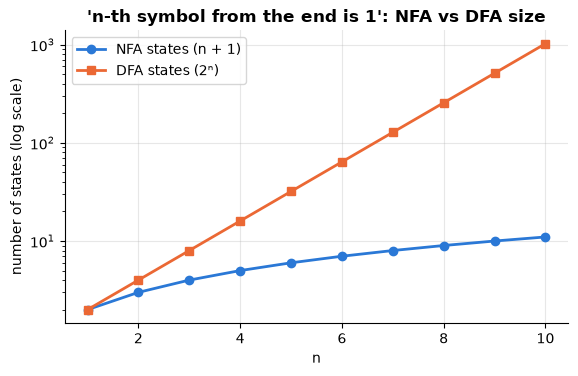

In [6]:
rows = []
for n in range(1, 11):
    nfa = nth_from_last_is_1(n)
    t0 = time.perf_counter()
    dfa = subset_construction(nfa)
    rows.append({"n": n, "NFA states": len(nfa.states), "DFA states (reachable subsets)": len(dfa.states),
                 "2^n": 2 ** n, "build time (ms)": round(1000 * (time.perf_counter() - t0), 1)})
blowup = pd.DataFrame(rows).set_index("n")
display(blowup)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(blowup.index, blowup["NFA states"], "o-", label="NFA states (n + 1)")
ax.semilogy(blowup.index, blowup["DFA states (reachable subsets)"], "s-", label="DFA states (2ⁿ)")
ax.set_xlabel("n"); ax.set_ylabel("number of states (log scale)")
ax.set_title("'n-th symbol from the end is 1': NFA vs DFA size"); ax.legend()
plt.show()

---
## 5. Regular expressions and Thompson's construction

> **In plain English:** a regular expression is a compact pattern, and it can be turned mechanically into an automaton that matches it.

**Definition (regular expressions over Σ).** Built recursively:

| Regex | Language |
|---|---|
| ∅ | the empty language |
| ε | {ε} |
| a (for a ∈ Σ) | {a} |
| $R \mid S$ (union) | $L(R) \cup L(S)$ |
| $RS$ (concatenation) | $L(R)L(S)$ |
| $R^*$ (Kleene star) | $L(R)^*$ |

Precedence: star binds tightest, then concatenation, then |. So `ab|c*` means `(ab)|(c*)`. Everyday regex syntax adds **sugar** that does not add power: $R^+ = RR^*$, $R? = R \mid \varepsilon$, character classes `[0-9]` = 0|1|…|9.

**Kleene's theorem (1956).** A language is regular ⇔ some regular expression describes it ⇔ some NFA recognises it ⇔ some DFA recognises it.

**Thompson's construction (1968)** turns a regex into an ε-NFA by gluing small fragments, each with one start and one accept state:

```
 a:      (s) --a--> (t)

 R|S:         ε--> [ R ] --ε
          (s)                (t)
              ε--> [ S ] --ε

 RS:     [ R ] --ε--> [ S ]

 R*:     (s) --ε--> [ R ] --ε--> (t)        plus  ε: s -> t   (zero copies)
                      ^  |                  and   ε: end of R -> start of R  (repeat)
                      └ε─┘
```
The NFA has at most 2 states per symbol or operator of the regex, so it is **linear in the size of the regex**. Below we write a small parser (recursive descent, see the next notebook for the theory), the construction, and a matcher, then test the engine against Python's `re.fullmatch` on hundreds of random regexes.

In [7]:
SPECIAL = set("|*+?()[]\\")

def parse_regex(pattern):
    """Recursive-descent parser. Grammar (lowest precedence first):
         alt    := concat ('|' concat)*
         concat := repeat*                      (empty concat = ε)
         repeat := atom ('*' | '+' | '?')*
         atom   := char | '\\' char | '[' class ']' | '(' alt ')'
       Returns an AST of tuples such as ('cat', A, B)."""
    pos = 0
    def peek():
        return pattern[pos] if pos < len(pattern) else None
    def eat(ch=None):
        nonlocal pos
        c = pattern[pos]
        assert ch is None or c == ch, f"expected {ch!r} at position {pos}"
        pos += 1
        return c
    def alt():
        node = concat()
        while peek() == "|":
            eat("|"); node = ("alt", node, concat())
        return node
    def concat():
        node = ("eps",)
        while peek() is not None and peek() not in "|)":
            nxt = repeat()
            node = nxt if node == ("eps",) else ("cat", node, nxt)
        return node
    def repeat():
        node = atom()
        while peek() in ("*", "+", "?"):
            node = ({"*": "star", "+": "plus", "?": "opt"}[eat()], node)
        return node
    def atom():
        c = peek()
        if c == "(":
            eat("("); node = alt(); eat(")")
            return node
        if c == "[":
            eat("["); chars = set()
            while peek() != "]":
                lo = eat()
                if peek() == "-" and pattern[pos + 1] != "]":
                    eat("-"); hi = eat()
                    chars |= {chr(x) for x in range(ord(lo), ord(hi) + 1)}
                else:
                    chars.add(lo)
            eat("]")
            return ("class", frozenset(chars))
        if c == "\\":
            eat("\\"); return ("char", eat())
        assert c not in SPECIAL, f"unexpected {c!r} at position {pos}"
        return ("char", eat())
    tree = alt()
    assert pos == len(pattern), f"unexpected {pattern[pos]!r} at position {pos}"
    return tree

def thompson(tree):
    """Regex AST -> ε-NFA. Each fragment is (start, accept)."""
    delta = defaultdict(set)
    counter = [0]
    alphabet = set()
    def new():
        counter[0] += 1
        return counter[0] - 1
    def build(node):
        kind = node[0]
        s, t = new(), new()
        if kind == "eps":
            delta[(s, EPS)].add(t)
        elif kind in ("char", "class"):
            for ch in ([node[1]] if kind == "char" else node[1]):
                delta[(s, ch)].add(t); alphabet.add(ch)
        elif kind == "cat":
            a1, b1 = build(node[1]); a2, b2 = build(node[2])
            delta[(s, EPS)].add(a1); delta[(b1, EPS)].add(a2); delta[(b2, EPS)].add(t)
        elif kind == "alt":
            for child in node[1:]:
                a, b = build(child)
                delta[(s, EPS)].add(a); delta[(b, EPS)].add(t)
        elif kind in ("star", "plus", "opt"):
            a, b = build(node[1])
            delta[(s, EPS)].add(a); delta[(b, EPS)].add(t)
            if kind in ("star", "opt"):
                delta[(s, EPS)].add(t)                  # zero copies allowed
            if kind in ("star", "plus"):
                delta[(b, EPS)].add(a)                  # repeat
        return s, t
    start, accept = build(tree)
    return NFA(range(counter[0]), alphabet, delta, start, {accept})

def regex_nfa(pattern, alphabet=None):
    nfa = thompson(parse_regex(pattern))
    if alphabet:
        nfa.alphabet = sorted(set(nfa.alphabet) | set(alphabet))
    return nfa

def fullmatch(pattern, text):
    return regex_nfa(pattern).accepts(text)

print("AST of (a|b)*abb:", parse_regex("(a|b)*abb"))
for pat, txt in [("(a|b)*abb", "babb"), ("(a|b)*abb", "abba"), ("colou?r", "color"), ("[0-9]+(\\.[0-9]+)?", "3.14"),
                 ("[0-9]+(\\.[0-9]+)?", "3."), ("(ab)+|c*", ""), ("(ab)+|c*", "abab")]:
    print(f"{pat:22s} {txt!r:8s} ours={fullmatch(pat, txt)!s:5s} re={re.fullmatch(pat, txt) is not None}")

AST of (a|b)*abb: ('cat', ('cat', ('cat', ('star', ('alt', ('char', 'a'), ('char', 'b'))), ('char', 'a')), ('char', 'b')), ('char', 'b'))
(a|b)*abb              'babb'   ours=True  re=True
(a|b)*abb              'abba'   ours=False re=False
colou?r                'color'  ours=True  re=True
[0-9]+(\.[0-9]+)?      '3.14'   ours=True  re=True
[0-9]+(\.[0-9]+)?      '3.'     ours=False re=False
(ab)+|c*               ''       ours=True  re=True
(ab)+|c*               'abab'   ours=True  re=True


Now the real test: generate 250 random regexes over {a, b} (using every operator, nested), and compare our engine with Python's `re.fullmatch` on **every** string over {a, b} up to length 6 (127 strings each). Our matcher simulates the NFA set-by-set, so its running time is O(length of text × size of regex) no matter what the pattern is.

In [8]:
def random_regex(rng, depth):
    """A random regex over {a, b}. Quantifiers are applied to a parenthesised group, so the
    pattern is also valid for Python's re (which rejects stacked quantifiers like a**)."""
    if depth == 0 or rng.random() < 0.25:
        return rng.choice(["a", "b", "[ab]", "a", "b"])
    kind = rng.choice(["cat", "cat", "alt", "star", "plus", "opt"])
    if kind == "cat":
        return random_regex(rng, depth - 1) + random_regex(rng, depth - 1)
    if kind == "alt":
        return "(" + random_regex(rng, depth - 1) + "|" + random_regex(rng, depth - 1) + ")"
    return "(" + random_regex(rng, depth - 1) + ")" + {"star": "*", "plus": "+", "opt": "?"}[kind]

rng = random.Random(0)
texts = strings_up_to("ab", 6)
n_checks, examples = 0, []
for _ in range(250):
    pat = random_regex(rng, 4)
    nfa = regex_nfa(pat, "ab")
    compiled = re.compile(pat)
    for t in texts:
        assert nfa.accepts(t) == (compiled.fullmatch(t) is not None), (pat, t)
        n_checks += 1
    if len(examples) < 5:
        examples.append((pat, len(nfa.states), sum(nfa.accepts(t) for t in texts)))
print(f"our Thompson engine agrees with re.fullmatch on {n_checks:,} (regex, string) pairs")
for pat, ns, k in examples:
    print(f"  e.g. {pat:40s} NFA states: {ns:3d}, accepts {k:3d} of {len(texts)} strings")

our Thompson engine agrees with re.fullmatch on 31,750 (regex, string) pairs
  e.g. (b)*                                     NFA states:   4, accepts   7 of 127 strings
  e.g. (((b|a)(b|b)|(a|([ab])?))|(ba|([ab])+)b) NFA states:  42, accepts  65 of 127 strings
  e.g. (((a)+)?)*([ab]|bb)                      NFA states:  20, accepts  17 of 127 strings
  e.g. ([ab])*                                  NFA states:   4, accepts 127 of 127 strings
  e.g. (b)*                                     NFA states:   4, accepts   7 of 127 strings


**What just happened?** On 31,750 (regex, string) pairs our ~100-line engine gave exactly the same answers as Python's production engine. That is strong evidence (not proof) that the parser and the construction are right.

Now the full pipeline **regex → ε-NFA → DFA** on the classic textbook example `(a|b)*abb` (the "dragon book" example of Aho, Lam, Sethi and Ullman):

Thompson ε-NFA: 20 states; subset-construction DFA: 5 states


,a,b
→ D0,D1,D2
D1,D1,D3
D2,D1,D2
D3,D1,D4
D4 *,D1,D2


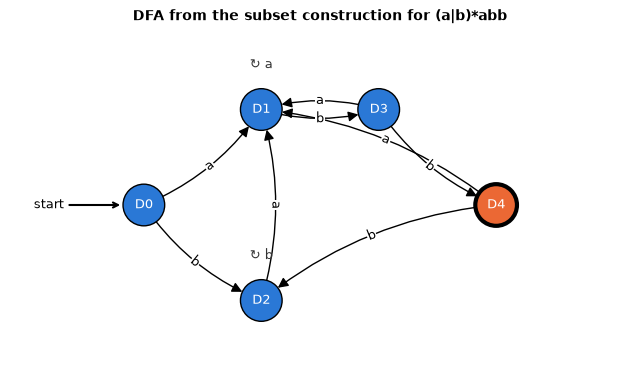

In [9]:
nfa_abb = regex_nfa("(a|b)*abb")
dfa_abb, names_abb = relabel(subset_construction(nfa_abb))
print(f"Thompson ε-NFA: {len(nfa_abb.states)} states; subset-construction DFA: {len(dfa_abb.states)} states")
display(dfa_abb.table())
fig, ax = plt.subplots(figsize=(8, 4.5))
draw_automaton(dfa_abb.states, dfa_transitions(dfa_abb), dfa_abb.start, dfa_abb.accept, ax,
               "DFA from the subset construction for (a|b)*abb",
               pos={"D0": (0, 0), "D1": (1, 0.8), "D2": (1, -0.8), "D3": (2, 0.8), "D4": (3, 0)})
plt.show()

---
## 6. DFA minimisation and regex equivalence

> **In plain English:** merge states that behave identically to get the smallest possible machine, which also tells us when two patterns mean the same thing.

**Distinguishable states.** Two states p and q are **distinguishable** if some string w leads one of them to acceptance and the other not. Otherwise they are **equivalent** and can be merged. The **Myhill–Nerode theorem** says every regular language has a *unique* (up to renaming) DFA with the fewest states, obtained by merging all equivalent states.

**Table-filling algorithm (Moore, 1956; as in Hopcroft–Motwani–Ullman).** Work on a complete DFA (add a dead state if needed) with unreachable states removed.
1. Mark every pair {p, q} where exactly one is accepting (ε distinguishes them).
2. Repeat until nothing changes: mark {p, q} if, for some symbol a, the pair {δ(p, a), δ(q, a)} is already marked.
3. Unmarked pairs are equivalent; merge them.

This takes O(|Q|² · |Σ|) per round and at most |Q| rounds. **Hopcroft's algorithm** (1971) does the same job in O(|Σ| · |Q| log |Q|) by refining partitions cleverly.

In [10]:
DEAD = "∅"

def complete(dfa):
    """Add an explicit dead state so that every (state, symbol) has a transition."""
    delta = dict(dfa.delta)
    states = list(dfa.states)
    need_dead = any((q, a) not in delta for q in states for a in dfa.alphabet)
    if need_dead:
        states.append(DEAD)
        for q in states:
            for a in dfa.alphabet:
                delta.setdefault((q, a), DEAD)
    return DFA(states, dfa.alphabet, delta, dfa.start, dfa.accept)

def reachable(dfa):
    seen, queue = {dfa.start}, deque([dfa.start])
    while queue:
        q = queue.popleft()
        for a in dfa.alphabet:
            r = dfa.delta.get((q, a))
            if r is not None and r not in seen:
                seen.add(r); queue.append(r)
    return seen

def table_filling(dfa, trace=False):
    """Return the equivalence classes of states (as frozensets), and optionally when each pair was marked."""
    d = complete(dfa)
    Q = [q for q in d.states if q in reachable(d)]
    marked = {}                                                    # pair -> round in which it was marked
    pairs = [frozenset((p, q)) for i, p in enumerate(Q) for q in Q[i + 1:]]
    for pr in pairs:
        p, q = tuple(pr)
        if (p in d.accept) != (q in d.accept):
            marked[pr] = 0
    rnd, changed = 0, True
    while changed:
        changed, rnd = False, rnd + 1
        for pr in pairs:
            if pr in marked:
                continue
            p, q = tuple(pr)
            for a in d.alphabet:
                succ = frozenset((d.delta[(p, a)], d.delta[(q, a)]))
                if len(succ) == 2 and succ in marked:
                    marked[pr] = rnd; changed = True
                    break
    # Unmarked pairs are equivalent: group states into classes
    classes = []
    for q in Q:
        for c in classes:
            if frozenset((q, next(iter(c)))) not in marked:
                c.add(q); break
        else:
            classes.append({q})
    classes = [frozenset(c) for c in classes]
    return (classes, marked, Q) if trace else classes

def minimize(dfa):
    """Merge equivalent states; drop the dead state again (it is left implicit)."""
    d = complete(dfa)
    classes = table_filling(d)
    cls_of = {q: c for c in classes for q in c}
    dead_classes = {c for c in classes if not any(q in d.accept for q in c)
                    and all(cls_of[d.delta[(q, a)]] == c for q in c for a in d.alphabet)}  # rejecting traps
    delta = {}
    for c in classes:
        if c in dead_classes:
            continue
        q = next(iter(c))
        for a in d.alphabet:
            target = cls_of[d.delta[(q, a)]]
            if target not in dead_classes:
                delta[(c, a)] = target
    states = [c for c in classes if c not in dead_classes]
    m = DFA(states, d.alphabet, delta, cls_of[d.start], {c for c in states if c & d.accept})
    return relabel(m, "M")[0]

def partition_refinement(dfa):
    """Moore's algorithm, an independent check: refine {F, Q-F} until stable. Returns the number of classes."""
    d = complete(dfa)
    Q = [q for q in d.states if q in reachable(d)]
    block = {q: int(q in d.accept) for q in Q}
    while True:
        sig = {q: (block[q],) + tuple(block[d.delta[(q, a)]] for a in d.alphabet) for q in Q}
        ids = {s: i for i, s in enumerate(sorted(set(sig.values())))}
        new = {q: ids[sig[q]] for q in Q}
        if len(set(new.values())) == len(set(block.values())):
            return len(set(new.values()))
        block = new

# Trace the table-filling algorithm on the DFA for (a|b)*abb
classes, marked, Q = table_filling(dfa_abb, trace=True)
tbl = pd.DataFrame("", index=Q, columns=Q)
for i, p in enumerate(Q):
    for q in Q[:i]:
        pr = frozenset((p, q))
        tbl.loc[p, q] = f"x{marked[pr]}" if pr in marked else "≡"
print("table-filling (xk = marked in round k, ≡ = never marked, so equivalent):")
display(tbl.iloc[1:, :-1])
print("equivalence classes:", [sorted(c) for c in classes])
min_abb = minimize(dfa_abb)
print(f"minimal DFA for (a|b)*abb has {len(min_abb.states)} states")
display(min_abb.table())
for w in strings_up_to("ab", 10):
    assert min_abb.accepts(w) == dfa_abb.accepts(w) == w.endswith("abb")

table-filling (xk = marked in round k, ≡ = never marked, so equivalent):


,D0,D1,D2,D3
D1,x2,,,
D2,≡,x2,,
D3,x1,x1,x1,
D4,x0,x0,x0,x0


equivalence classes: [['D0', 'D2'], ['D1'], ['D3'], ['D4']]
minimal DFA for (a|b)*abb has 4 states


,a,b
→ M0,M1,M0
M1,M1,M2
M2,M1,M3
M3 *,M1,M0


**What just happened?** In round 0 every accepting/non-accepting pair was marked; later rounds marked pairs whose successors were already distinguishable. The one pair left unmarked (≡) consists of two states that behave identically on every future input, so they merge, and the minimal DFA has **4 states**: it remembers how much of the suffix "abb" it has just seen (nothing, a, ab, abb). This matches the dragon-book answer.

Next we check minimisation in bulk. For random regexes: (1) the minimal DFA accepts exactly the same strings, (2) our table-filling and an independent partition-refinement implementation find the same number of states, and (3) the "n-th from last" DFAs really cannot be shrunk below $2^n$.

In [11]:
rng = random.Random(1)
texts = strings_up_to("ab", 7)
sizes = []
for _ in range(80):
    pat = random_regex(rng, 4)
    dfa = subset_construction(regex_nfa(pat, "ab"))
    m = minimize(dfa)
    assert all(m.accepts(t) == dfa.accepts(t) for t in texts)
    n_live = len(m.states) + (1 if any((q, a) not in m.delta for q in m.states for a in m.alphabet) else 0)
    assert n_live == partition_refinement(dfa)                    # same count, dead state included
    sizes.append((len(dfa.states), len(m.states)))
print(f"80 random regexes: minimal DFAs are equivalent and match partition refinement; "
      f"average states {np.mean([s for s, _ in sizes]):.1f} -> {np.mean([m for _, m in sizes]):.1f} after minimisation")
print("minimal DFA sizes for 'n-th from last is 1':",
      {n: len(minimize(subset_construction(nth_from_last_is_1(n))).states) for n in range(1, 8)})

80 random regexes: minimal DFAs are equivalent and match partition refinement; average states 3.6 -> 2.9 after minimisation


minimal DFA sizes for 'n-th from last is 1': {1: 2, 2: 4, 3: 8, 4: 16, 5: 32, 6: 64, 7: 128}


### Deciding whether two regexes are equivalent
Because the minimal DFA is **unique**, two regexes describe the same language iff their minimal DFAs are identical after renaming states in a canonical way (BFS from the start, symbols in alphabetical order). This is a complete decision procedure, which is remarkable: for programs in general, equivalence is undecidable (next notebook).

In [12]:
def canonical(dfa):
    m = minimize(dfa)
    return (len(m.states), tuple(sorted(m.delta.items())), m.start, tuple(sorted(m.accept)))

def equivalent(r1, r2, alphabet="ab"):
    d1 = subset_construction(regex_nfa(r1, alphabet))
    d2 = subset_construction(regex_nfa(r2, alphabet))
    return canonical(d1) == canonical(d2)

for r1, r2 in [("(a|b)*", "(a*b*)*"), ("(ab)*a", "a(ba)*"), ("a*b*", "(a|b)*"), ("(a|b)*abb", "(a|b)*ab(b)"),
               ("a(a|b)*", "a+(b|a)*"), ("(a*|b)*", "(a|b)*"), ("ab|ba", "(a|b)(a|b)")]:
    print(f"{r1:12s} ≡ {r2:12s} ? {equivalent(r1, r2)}")

(a|b)*       ≡ (a*b*)*      ? True
(ab)*a       ≡ a(ba)*       ? True
a*b*         ≡ (a|b)*       ? False
(a|b)*abb    ≡ (a|b)*ab(b)  ? True
a(a|b)*      ≡ a+(b|a)*     ? True
(a*|b)*      ≡ (a|b)*       ? True
ab|ba        ≡ (a|b)(a|b)   ? False


---
## 7. Closure properties and decision problems

> **In plain English:** combining regular languages with and, or and not always gives another regular language.

The regular languages are **closed** under many operations: apply the operation to regular languages and the result is regular.

| Operation | Why it stays regular |
|---|---|
| Union $L_1 \cup L_2$ | regex $R_1 \mid R_2$, or the product construction |
| Concatenation, star | regex $R_1R_2$, $R^*$ |
| **Complement** $\overline{L}$ | complete DFA, swap accepting and non-accepting states |
| **Intersection** $L_1 \cap L_2$ | **product construction**: run both DFAs in parallel on pairs of states |
| Difference $L_1 - L_2$ | $L_1 \cap \overline{L_2}$ |
| Reversal $L^R$ | reverse every arrow of an NFA, swap start and accept (via a new ε start) |
| Homomorphism, inverse homomorphism | substitute strings for symbols |

**Product construction.** States are pairs $(p, q)$; $\delta((p, q), a) = (\delta_1(p, a), \delta_2(q, a))$; for ∩ accept when both accept, for ∪ when either does, for − when the first does and the second does not.

**Decision problems** for regular languages are all decidable from a DFA: **membership** (run it, O(n)), **emptiness** (is any accepting state reachable? graph search), **finiteness** (is there a reachable cycle that can reach an accepting state?), **equivalence** (compare minimal DFAs, or check that the symmetric difference is empty).

In [13]:
def product_dfa(d1, d2, mode):
    """Product construction for 'and' (∩), 'or' (∪) and 'diff' (L1 − L2)."""
    d1, d2 = complete(d1), complete(d2)
    assert d1.alphabet == d2.alphabet
    start = (d1.start, d2.start)
    delta, seen, queue = {}, {start}, deque([start])
    while queue:
        p, q = queue.popleft()
        for a in d1.alphabet:
            nxt = (d1.delta[(p, a)], d2.delta[(q, a)])
            delta[((p, q), a)] = nxt
            if nxt not in seen:
                seen.add(nxt); queue.append(nxt)
    test = {"and": lambda x, y: x and y, "or": lambda x, y: x or y, "diff": lambda x, y: x and not y}[mode]
    accept = {(p, q) for (p, q) in seen if test(p in d1.accept, q in d2.accept)}
    return DFA(list(seen), d1.alphabet, delta, start, accept)

def complement(dfa):
    d = complete(dfa)
    return DFA(d.states, d.alphabet, d.delta, d.start, set(d.states) - d.accept)

def is_empty(dfa):
    return not (reachable(dfa) & dfa.accept)

even_a = DFA(["e", "o"], "ab", {("e", "a"): "o", ("o", "a"): "e", ("e", "b"): "e", ("o", "b"): "o"}, "e", {"e"})
ends_b = subset_construction(regex_nfa("(a|b)*b", "ab"))
both = product_dfa(even_a, ends_b, "and")
for w in strings_up_to("ab", 10):
    assert both.accepts(w) == (w.count("a") % 2 == 0 and w.endswith("b"))
    assert complement(even_a).accepts(w) == (w.count("a") % 2 == 1)
print(f"'even number of a's' ∩ 'ends in b': product DFA with {len(both.states)} states "
      f"(minimal: {len(minimize(both).states)}), verified on all strings up to length 10")

# Equivalence via emptiness of the symmetric difference
def equivalent_by_product(r1, r2, alphabet="ab"):
    d1 = subset_construction(regex_nfa(r1, alphabet)); d2 = subset_construction(regex_nfa(r2, alphabet))
    return is_empty(product_dfa(d1, d2, "diff")) and is_empty(product_dfa(d2, d1, "diff"))
print("(a|b)* vs (a*b*)* equivalent by product test:", equivalent_by_product("(a|b)*", "(a*b*)*"),
      "| a*b* vs (a|b)*:", equivalent_by_product("a*b*", "(a|b)*"))

'even number of a's' ∩ 'ends in b': product DFA with 5 states (minimal: 3), verified on all strings up to length 10
(a|b)* vs (a*b*)* equivalent by product test: True | a*b* vs (a|b)*: False


---
## 8. Proving a language is not regular

> **In plain English:** a machine with finitely many states cannot count without limit, so some patterns (like matched brackets) are impossible for regex.

A DFA has finitely many states, so it has **finite memory**. Languages that need to count without bound are not regular. Two standard proof tools:

### 8.1 The pumping lemma for regular languages
**Lemma.** If L is regular, there is a number p (the **pumping length**) such that every $s \in L$ with $|s| \ge p$ can be split as $s = xyz$ with
1. $|y| \ge 1$,
2. $|xy| \le p$,
3. $xy^iz \in L$ for **every** $i \ge 0$.

*Proof.* Let p be the number of states of a DFA for L. Reading the first p symbols of s visits p + 1 states, so by the **pigeonhole principle** ([notebook 02](02_combinatorics_and_recurrences.ipynb)) some state repeats. Let x lead to the first visit, y go around the loop back to the same state, and z be the rest. Going around the loop i times instead of once (including zero times) ends in the same accepting state. ∎

The code below does exactly this on a real DFA: it finds the repeated state, extracts x, y, z, and checks that pumping keeps the string in the language.

In [14]:
def pump_split(dfa, s):
    """Find x, y, z for s (|s| >= number of states) from the first repeated state, as in the proof."""
    states = dfa.run(s)
    first_seen = {}
    for i, q in enumerate(states):
        if q in first_seen:
            j0 = first_seen[q]
            return s[:j0], s[j0:i], s[i:]
        first_seen[q] = i
    raise ValueError("no repeated state (string shorter than the number of states?)")

p = len(div3.states)
for s in ["110", "1001", "111111", "10010110"]:
    x, y, z = pump_split(div3, s)
    pumped = [x + y * i + z for i in range(5)]
    ok = all(div3.accepts(t) for t in pumped)
    print(f"s = {s:9s} ({int(s, 2):3d}) x={x!r:6s} y={y!r:5s} z={z!r:8s} -> x y^i z for i=0..4:",
          [int(t, 2) if t else 0 for t in pumped], "all divisible by 3:", ok)
    assert ok and len(x + y) <= p and len(y) >= 1

s = 110       (  6) x=''     y='11'  z='0'      -> x y^i z for i=0..4: [0, 6, 30, 126, 510] all divisible by 3: True
s = 1001      (  9) x='1'    y='00'  z='1'      -> x y^i z for i=0..4: [3, 9, 33, 129, 513] all divisible by 3: True
s = 111111    ( 63) x=''     y='11'  z='1111'   -> x y^i z for i=0..4: [15, 63, 255, 1023, 4095] all divisible by 3: True
s = 10010110  (150) x='1'    y='00'  z='10110'  -> x y^i z for i=0..4: [54, 150, 534, 2070, 8214] all divisible by 3: True


### 8.2 Using the lemma: $\{a^nb^n \mid n \ge 0\}$ is not regular
The lemma is used **by contradiction**, as a game against an adversary:
1. Assume L is regular; the adversary picks p.
2. **You** pick a string s ∈ L with |s| ≥ p (choose it cleverly).
3. The adversary picks *any* split s = xyz obeying rules 1 and 2.
4. **You** pick an i with $xy^iz \notin L$. Contradiction.

For $L = \{a^nb^n\}$: choose $s = a^pb^p$. Since $|xy| \le p$, both x and y lie inside the a's, so $y = a^k$ with k ≥ 1. Then $xy^2z = a^{p+k}b^p \notin L$. So L is not regular. ∎

The code plays the adversary for every p up to 15 and tries **every** legal split.

In [15]:
in_anbn = lambda w: (len(w) % 2 == 0 and w == "a" * (len(w) // 2) + "b" * (len(w) // 2))
total_splits = 0
for p in range(1, 16):
    s = "a" * p + "b" * p
    for i in range(0, p + 1):                       # |x| = i
        for j in range(i + 1, p + 1):               # |xy| = j <= p, |y| = j - i >= 1
            x, y, z = s[:i], s[i:j], s[j:]
            assert not in_anbn(x + y * 2 + z)       # pumping up breaks it
            assert not in_anbn(x + z)               # pumping down breaks it too
            total_splits += 1
print(f"for every p = 1..15 and all {total_splits} legal splits of a^p b^p, pumping leaves the language")

# Python's re is MORE than regular: backreferences recognise a^n b a^n, which no DFA can
backref = re.compile(r"(a*)b\1")
print("re with a backreference, (a*)b\\1:", [w for w in ["aba", "aabaa", "aaba", "b", "aaabaaa"] if backref.fullmatch(w)])

for every p = 1..15 and all 680 legal splits of a^p b^p, pumping leaves the language
re with a backreference, (a*)b\1: ['aba', 'aabaa', 'b', 'aaabaaa']


**What just happened?** Every one of the 680 legal ways to split $a^pb^p$ (for p up to 15) fails to pump, confirming the proof's case analysis. The last line shows that Python's `re` is not a pure regular-expression engine: **backreferences** like `\1` can match $a^nba^n$, which is not regular. That extra power has a price, discussed in Section 9.

### 8.3 Balanced parentheses are not regular (via closure)
Let B be the language of balanced parentheses. If B were regular, then $B \cap L(\texttt{(*)*}) = \{(^n)^n\}$ would be regular too (closure under intersection). But that is $a^nb^n$ with a = `(` and b = `)`, which we just proved is not regular. So **B is not regular**: no regex can check nested brackets, HTML tags or JSON nesting to arbitrary depth. That needs a **pushdown automaton** (a DFA plus a stack), the subject of the next notebook.

### 8.4 Myhill–Nerode: an exact characterisation
Strings x and y are **distinguishable** by L if some suffix z has exactly one of xz, yz in L. **Myhill–Nerode theorem:** L is regular iff it has finitely many pairwise-distinguishable classes, and the number of classes is the size of the minimal DFA. For $a^nb^n$, the prefixes $a^0, a^1, a^2, \dots$ are pairwise distinguishable (suffix $b^i$ accepts $a^i$ but not $a^j$), so there are infinitely many classes. Unlike the pumping lemma, Myhill–Nerode is an "iff", so it can also prove regularity.

> ⚠️ **Common mistake:** using the pumping lemma to prove a language **is** regular. The lemma is a necessary condition only. Some non-regular languages satisfy it (for example $\{a^ib^jc^k \mid i = 0 \text{ or } j = k\}$), so "it pumps" proves nothing.

In [16]:
# Myhill-Nerode for a^n b^n: the prefixes a^i are pairwise distinguished by the suffix b^i
N = 8
dist = pd.DataFrame([[("b" * i if i != j else "-") for j in range(N)] for i in range(N)],
                    index=[f"a^{i}" for i in range(N)], columns=[f"a^{j}" for j in range(N)])
for i in range(N):
    for j in range(N):
        if i != j:
            assert in_anbn("a" * i + "b" * i) and not in_anbn("a" * j + "b" * i)
print("suffix that distinguishes prefix a^i (row) from a^j (column):")
display(dist.iloc[:6, :6])

suffix that distinguishes prefix a^i (row) from a^j (column):


,a^0,a^1,a^2,a^3,a^4,a^5
a^0,-,,,,,
a^1,b,-,b,b,b,b
a^2,bb,bb,-,bb,bb,bb
a^3,bbb,bbb,bbb,-,bbb,bbb
a^4,bbbb,bbbb,bbbb,bbbb,-,bbbb
a^5,bbbbb,bbbbb,bbbbb,bbbbb,bbbbb,-


---
## 9. Regex in production: catastrophic backtracking (ReDoS)

> **In plain English:** some real regex engines can take exponentially long on unlucky input, which attackers can exploit.

Python's `re`, and the regex engines of Java, JavaScript, .NET, Perl and PCRE, are **backtracking** engines: they try one way to match, and on failure back up and try another. That is what makes backreferences possible, but on some patterns the number of ways to try is **exponential** in the input length. An attacker who can send input to such a pattern can freeze a server: a **regular-expression denial of service (ReDoS)**.

The classic bad pattern is a nested quantifier such as `(a+)+$`. Against `aaaa…a!` the engine tries every way of splitting the a's between the inner and outer `+` (there are $2^{n-1}$) before concluding there is no match.

Real incidents: a Stack Overflow outage in July 2016 (a whitespace-trimming regex hit a post with about 20,000 consecutive spaces) and a global Cloudflare outage on 2 July 2019 (a regex in a firewall rule exhausted CPUs worldwide for about half an hour).

Thompson's NFA simulation (Section 5) cannot blow up: it keeps a *set* of states and never backtracks. Engines built this way (Google's **RE2**, Rust's `regex`, Go's `regexp`) guarantee linear time, at the cost of not supporting backreferences.

time in milliseconds to reject 'a' * n + '!':


,re: (a+)+,re: (?>a+)+ atomic,re: a+ rewritten,our NFA: (a+)+
n,,,,
12,0.331,0.003,0.002,0.077
14,10.500,0.006,0.002,4.084
16,38.850,0.006,0.001,0.087
18,121.893,0.007,0.003,0.140
20,513.454,0.007,0.002,0.101
22,2068.043,0.008,0.002,0.137


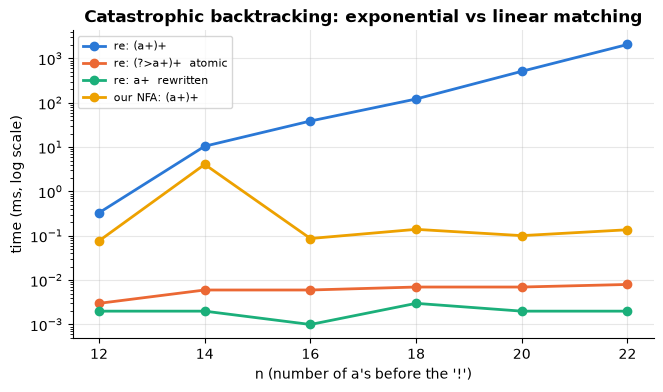

backtracking time grows by about ×2.0 per extra character


In [17]:
ns = list(range(12, 23, 2))
rows = []
bad = re.compile(r"(a+)+")
atomic = re.compile(r"(?>a+)+")          # atomic group (Python 3.11+): no backtracking into the group
simple = re.compile(r"a+")               # the same language, written without nesting
ours = regex_nfa("(a+)+", "a!")
for n in ns:
    s = "a" * n + "!"
    t = {}
    for name, fn in [("re: (a+)+", lambda: bad.fullmatch(s)), ("re: (?>a+)+  atomic", lambda: atomic.fullmatch(s)),
                     ("re: a+  rewritten", lambda: simple.fullmatch(s)), ("our NFA: (a+)+", lambda: ours.accepts(s))]:
        t0 = time.perf_counter(); result = fn(); t[name] = 1000 * (time.perf_counter() - t0)
        assert not result                                    # no engine matches 'aaa...a!'
    rows.append({"n": n, **{k: round(v, 3) for k, v in t.items()}})
redos = pd.DataFrame(rows).set_index("n")
print("time in milliseconds to reject 'a' * n + '!':")
display(redos)
fig, ax = plt.subplots(figsize=(7.5, 4))
for col in redos.columns:
    ax.semilogy(redos.index, redos[col].clip(lower=1e-3), "o-", label=col)
ax.set_xlabel("n (number of a's before the '!')"); ax.set_ylabel("time (ms, log scale)")
ax.set_title("Catastrophic backtracking: exponential vs linear matching"); ax.legend(fontsize=8)
plt.show()
growth = (redos["re: (a+)+"].iloc[-1] / redos["re: (a+)+"].iloc[-2]) ** 0.5
print(f"backtracking time grows by about ×{growth:.1f} per extra character")

**What just happened?** The backtracking engine's time for `(a+)+` roughly **doubles with every extra character** (a straight line on the log scale), so a few more characters turn milliseconds into hours. The atomic group, the rewritten pattern `a+` (same language!) and our NFA simulation all stay flat. (The NFA line is higher than the `re` lines in absolute terms only because it is pure Python.)

**How to avoid ReDoS in practice:**
- avoid nested quantifiers over overlapping alternatives: `(a+)+`, `(a|a)*`, `(\w+\s?)*`;
- prefer a linear-time engine (RE2, Rust `regex`) for untrusted input;
- in Python ≥ 3.11 use atomic groups `(?>…)` or possessive quantifiers `a++` to forbid backtracking;
- limit input length and set timeouts;
- treat any regex that touches user input as attack surface in your threat model (see [`23_Software_Engineering/08_security_for_ai_applications.ipynb`](../../23_Software_Engineering/08_security_for_ai_applications.ipynb)).

---
## 10. Mealy and Moore machines

> **In plain English:** state machines that produce output as they go are how protocols, controllers and simple chatbots are designed.

A DFA only says yes or no at the end. **Transducers** produce output while they run; they are the standard way to design protocols, controllers and user-interface flows.

| | Moore machine (1956) | Mealy machine (1955) |
|---|---|---|
| output depends on | current **state** only | current state **and** current input |
| output function | $\lambda: Q \to \Gamma$ | $\lambda: Q \times \Sigma \to \Gamma$ |
| reacts to input | one step later | immediately |
| typical size | can need more states | can need fewer states |

Every Mealy machine can be converted to an equivalent Moore machine and vice versa (with output timing shifted by one step).

Below: a **Moore** machine that outputs the parity of the 1s seen so far, and a **Mealy** machine that outputs 1 exactly when the last three inputs were `101` (overlaps allowed), a classic digital-design exercise.

In [18]:
def run_moore(delta, output, start, inputs):
    q, out = start, [output[start]]                 # a Moore machine emits an output for the start state too
    for ch in inputs:
        q = delta[(q, ch)]
        out.append(output[q])
    return "".join(out)

def run_mealy(delta, start, inputs):
    q, out = start, []
    for ch in inputs:
        q, o = delta[(q, ch)]                       # transition gives (next state, output)
        out.append(o)
    return "".join(out)

parity_delta = {("even", "0"): "even", ("even", "1"): "odd", ("odd", "0"): "odd", ("odd", "1"): "even"}
parity_out = {"even": "0", "odd": "1"}

# Mealy '101' detector: states remember the longest suffix that is a prefix of '101'
det = {("",   "0"): ("",   "0"), ("",   "1"): ("1",  "0"),
       ("1",  "0"): ("10", "0"), ("1",  "1"): ("1",  "0"),
       ("10", "0"): ("",   "0"), ("10", "1"): ("1",  "1")}     # seeing 1 after '10' completes '101'

bits = "1101011010"
print("input:            ", bits)
print("Moore parity:     ", run_moore(parity_delta, parity_out, "even", bits), "(one extra symbol for the start state)")
print("Mealy '101' flags:", run_mealy(det, "", bits))
rng = random.Random(2)
for _ in range(500):
    w = "".join(rng.choice("01") for _ in range(rng.randint(0, 30)))
    assert run_mealy(det, "", w) == "".join("1" if w[max(0, i - 2): i + 1] == "101" else "0" for i in range(len(w)))
print("the '101' detector agrees with a direct check on 500 random inputs")

input:             1101011010
Moore parity:      01001101100 (one extra symbol for the start state)
Mealy '101' flags: 0001010010
the '101' detector agrees with a direct check on 500 random inputs


### A chatbot conversation flow as a finite-state machine
Before LLMs, nearly every customer-service bot was a finite-state machine: each state is a step of the conversation, each input is an **intent** (from a classifier or keyword rules), and the transition table decides what happens next. Even LLM agents today often keep an explicit FSM around the model for the parts that must be reliable (authentication, payment, hand-off to a human), and frameworks such as LangGraph ([`10_Agents/03_langgraph.ipynb`](../../10_Agents/03_langgraph.ipynb)) describe agents as graphs of states. The machine below is a Mealy machine: its output (the bot's reply) depends on the state and the input.

[START  ] user: salam!               intent=greet  -> [MENU   ] bot: Hello! What would you like to order: pizza, burger or biryani?
[MENU   ] user: do you have sushi?   intent=other  -> [MENU   ] bot: Sorry, I did not understand. You can say 'cancel' at any time.
[MENU   ] user: one biryani please   intent=order  -> [CONFIRM] bot: Great choice. Shall I place that order?
[CONFIRM] user: no, wrong            intent=no     -> [MENU   ] bot: No problem. What would you like instead?
[MENU   ] user: a pizza              intent=order  -> [CONFIRM] bot: Great choice. Shall I place that order?
[CONFIRM] user: yes                  intent=yes    -> [DONE   ] bot: Order placed. It will arrive in 30 minutes.


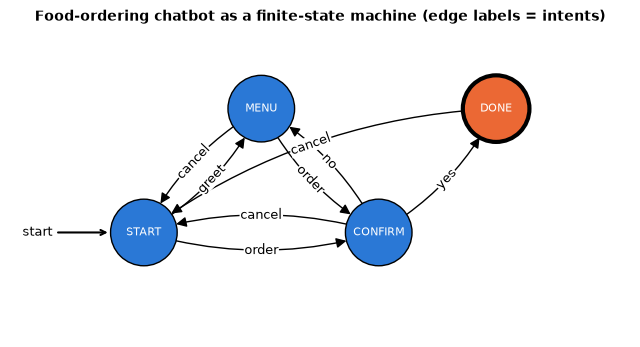

In [19]:
def intent(text):
    """A tiny keyword classifier: the 'input symbol' of our machine."""
    t = text.lower()
    for name, words in [("cancel", ["cancel", "stop"]), ("yes", ["yes", "yeah", "correct"]), ("no", ["no", "wrong"]),
                        ("greet", ["hi", "hello", "salam"]), ("order", ["pizza", "burger", "biryani"])]:
        if any(re.search(rf"\b{w}\b", t) for w in words):
            return name
    return "other"

BOT = {   # (state, intent) -> (next state, reply)
    ("START", "greet"): ("MENU", "Hello! What would you like to order: pizza, burger or biryani?"),
    ("START", "order"): ("CONFIRM", "Got it. Shall I place that order?"),
    ("MENU", "order"): ("CONFIRM", "Great choice. Shall I place that order?"),
    ("CONFIRM", "yes"): ("DONE", "Order placed. It will arrive in 30 minutes."),
    ("CONFIRM", "no"): ("MENU", "No problem. What would you like instead?"),
}
FALLBACK = "Sorry, I did not understand. You can say 'cancel' at any time."

def bot_step(state, text):
    i = intent(text)
    if i == "cancel":
        return "START", "Cancelled. Say hello to start again."
    return BOT.get((state, i), (state, FALLBACK))      # unknown input: stay in the same state

state = "START"
for user in ["salam!", "do you have sushi?", "one biryani please", "no, wrong", "a pizza", "yes"]:
    new_state, reply = bot_step(state, user)
    print(f"[{state:7s}] user: {user:20s} intent={intent(user):6s} -> [{new_state:7s}] bot: {reply}")
    state = new_state

tr = defaultdict(list)
for (p, i), (q, _) in BOT.items():
    tr[(p, q)].append(i)
for p in ["MENU", "CONFIRM", "DONE"]:
    tr[(p, "START")].append("cancel")
fig, ax = plt.subplots(figsize=(8, 4))
draw_automaton(["START", "MENU", "CONFIRM", "DONE"], tr, "START", {"DONE"}, ax,
               "Food-ordering chatbot as a finite-state machine (edge labels = intents)",
               pos={"START": (0, 0), "MENU": (1, 0.8), "CONFIRM": (2, 0), "DONE": (3, 0.8)}, node_size=2300, font_size=8)
plt.show()

**What just happened?** The scripted conversation walked START → MENU → (fallback, stays in MENU) → CONFIRM → MENU (user said no) → CONFIRM → DONE. Because the flow is a finite-state machine, it is **testable and auditable**: you can list every state, check that every state handles "cancel", and prove that DONE is only reachable through CONFIRM ("never place an order without a yes"), using the reachability checks from Section 7.

---
## 11. Summary table

> **In plain English:** every model and algorithm from this notebook on one page.

| Model / tool | What it is | Power | Key algorithm | Cost |
|---|---|---|---|---|
| DFA | one next state per (state, symbol) | regular languages | simulation | O(n) time, O(1) memory |
| NFA / ε-NFA | sets of next states, ε-moves | regular (same as DFA) | set simulation; subset construction | O(n·\|Q\|²); DFA may need $2^{\lvert Q\rvert}$ states |
| Regular expression | ∅, ε, a, \|, concatenation, * | regular (Kleene's theorem) | Thompson's construction | NFA linear in regex size |
| Minimal DFA | merge indistinguishable states | unique per language | table filling, Hopcroft | O(\|Q\|²\|Σ\|), O(\|Σ\|\|Q\| log \|Q\|) |
| Backtracking regex (Python `re`, PCRE) | regex + backreferences, lookaround | more than regular | backtracking | **exponential** worst case (ReDoS) |
| Mealy / Moore machine | DFA with outputs | transducers | simulation | O(n) |
| Not regular | needs unbounded memory | $a^nb^n$, balanced brackets, palindromes | pumping lemma, Myhill–Nerode, closure | (next notebook: pushdown automata) |

---
## 12. 🔗 How this connects to modern AI: constrained decoding

> **In plain English:** an automaton can block an AI model from ever producing output in the wrong format.

An LLM generates text one **token** at a time by sampling from a probability distribution over its vocabulary. Asked for JSON, it *usually* complies, but "usually" breaks production pipelines ([`08_LLM/17_structured_outputs.ipynb`](../../08_LLM/17_structured_outputs.ipynb) shows the failure modes and the retry-based fixes). **Constrained decoding** makes invalid output impossible instead:
1. Compile the required format (a regex, or a JSON schema converted to a regex or grammar) into a **DFA**.
2. Precompute, for every DFA state and every vocabulary token, the state reached after reading the token's characters (or "dead").
3. At each step, **mask** (set to −∞) the logits of tokens that would lead to a dead state, and allow end-of-sequence only in an accepting state.

Every sampled sequence then matches the regex by construction. This is the approach of Willard and Louf (2023), "Efficient Guided Generation for Large Language Models", implemented in the Outlines library; grammar-based variants (llama.cpp GBNF grammars, XGrammar, the structured-output modes of vLLM and hosted APIs) extend it from regular languages to context-free grammars, because nested JSON is not regular (Section 8.3).

Below we do it with a **toy language model** (random logits from a fixed seed) and a tiny multi-character vocabulary. Notice the subtlety that real systems face: tokens span several characters, so the mask is computed by running the DFA over each token's characters.

In [20]:
pattern = r'\{"name": "[a-z]+", "age": [1-9][0-9]?\}'
dfa_json = minimize(subset_construction(regex_nfa(pattern)))
print(f"regex {pattern}\n-> minimal DFA with {len(dfa_json.states)} states over an alphabet of {len(dfa_json.alphabet)} characters")

vocab = ['{', '}', '{"', '"', 'name', 'age', '": ', '":', ': ', '", "', ', ', ' ', 'na', 'me', 'ag', 'e',
         'ali', 'sara', 'zo', 'ya', 'x', 'q', 'Hello', '!!', 'null', '[', ']', 'True', '0', '1', '2', '7',
         '42', '19', '100', '"}', '<EOS>']
EOS = vocab.index('<EOS>')

def run_token(dfa, state, token):
    """State after reading all characters of `token` (None = dead)."""
    for ch in token:
        state = dfa.delta.get((state, ch))
        if state is None:
            return None
    return state

# Step 2: precompute the token index (DFA state x token -> next state), as Outlines does
index = {(q, t): run_token(dfa_json, q, tok) for q in dfa_json.states for t, tok in enumerate(vocab) if t != EOS}
allowed_counts = [sum(index[(q, t)] is not None for t in range(len(vocab)) if t != EOS) for q in dfa_json.states]
print(f"index: {len(index)} (state, token) entries; tokens allowed per state: min {min(allowed_counts)}, max {max(allowed_counts)}")

def generate(seed, constrained, max_tokens=200):
    rng_ = np.random.default_rng(seed)
    state, out = dfa_json.start, []
    for _ in range(max_tokens):
        logits = rng_.normal(0, 1.5, size=len(vocab))          # the toy "language model"
        if constrained:
            mask = np.full(len(vocab), -np.inf)
            for t in range(len(vocab)):
                if t == EOS:
                    ok = state in dfa_json.accept                 # may only stop in an accepting state
                else:
                    ok = index[(state, t)] is not None
                if ok:
                    mask[t] = 0.0
            logits = logits + mask                              # step 3: forbid invalid tokens
        probs = np.exp(logits - logits.max()); probs /= probs.sum()
        t = rng_.choice(len(vocab), p=probs)
        if t == EOS:
            break
        out.append(vocab[t])
        if constrained:
            state = index[(state, t)]
    return "".join(out)

print("\nUNCONSTRAINED samples:")
for seed in range(3):
    s = generate(seed, constrained=False)
    print(f"  {s[:70]!r:75s} valid: {re.fullmatch(pattern, s) is not None}")
print("CONSTRAINED samples:")
valid = 0
for seed in range(200):
    s = generate(seed, constrained=True)
    valid += re.fullmatch(pattern, s) is not None
    if seed < 5:
        print(f"  {s!r:75s} valid: {re.fullmatch(pattern, s) is not None}")
print(f"{valid} of 200 constrained samples match the regex (checked with Python's re)")
assert valid == 200

regex \{"name": "[a-z]+", "age": [1-9][0-9]?\}
-> minimal DFA with 25 states over an alphabet of 42 characters
index: 900 (state, token) entries; tokens allowed per state: min 0, max 15

UNCONSTRAINED samples:
  '42'                                                                        valid: False
  '100, 7 ali":yanull[ag0name, }!!7021910019alina":me": [", "TruesaraagqT'    valid: False
  ']1942"meag"ali}": ": zo 0[100saraxzo{"Hello42qageHellonull"":: True]42'    valid: False
CONSTRAINED samples:
  '{"name": "yaqnaqnaali", "age": 17}'                                        valid: True
  '{"name": "ageealisaraagnanameage", "age": 19}'                             valid: True
  '{"name": "namenaage", "age": 42}'                                          valid: True
  '{"name": "yananaagme", "age": 12}'                                         valid: True
  '{"name": "nanullnullxnamezoageesaranamealizomealinae", "age": 42}'         valid: True


200 of 200 constrained samples match the regex (checked with Python's re)


**What just happened?** The unconstrained toy model produces junk, as expected from random logits. With the DFA mask, **all 200 samples are valid** by construction, even though the "model" is the same random number generator: the automaton removes every token that could not lead to a valid string, and EOS is allowed only in the accepting state. A real LLM puts most of its probability on sensible tokens already, so the mask rarely changes its choice, but it turns "usually valid" into "always valid".

Other places where automata live inside AI systems:

| Where | What automaton | Link |
|---|---|---|
| **Tokenizers and lexers** | the pre-tokenisation step of BPE tokenizers splits text with a regex; compilers' lexers are DFAs built from regexes (lex/flex) | [`07_NLP/00_start_here_text_to_numbers.ipynb`](../../07_NLP/00_start_here_text_to_numbers.ipynb) |
| **Text cleaning and extraction** | regexes for emails, dates, IDs, PII masking | [`07_NLP/01_text_preprocessing.ipynb`](../../07_NLP/01_text_preprocessing.ipynb) |
| **Speech and spelling** | weighted finite-state transducers (WFSTs) in classical speech recognition decoders (Kaldi) and text normalisation | [`07_NLP/08_speech_and_audio.ipynb`](../../07_NLP/08_speech_and_audio.ipynb) |
| **Guardrails** | regex/FSM filters on inputs and outputs (with ReDoS-safe engines) | [`08_LLM/16_llm_security.ipynb`](../../08_LLM/16_llm_security.ipynb) |
| **Agents** | explicit state machines for reliable multi-step flows | [`10_Agents/03_langgraph.ipynb`](../../10_Agents/03_langgraph.ipynb) |
| **Structured output** | regex/grammar-constrained decoding | [`08_LLM/17_structured_outputs.ipynb`](../../08_LLM/17_structured_outputs.ipynb) |

---
## 13. Recap

> **In plain English:** the key facts to remember, then practice.

- A **language** is a set of strings over a finite alphabet; the regular operations are union, concatenation and star. ∅ ≠ {ε}.
- A **DFA** $(Q, \Sigma, \delta, q_0, F)$ reads input in O(n) time with O(1) memory. Design it by deciding what the machine must remember.
- An **NFA** may guess (several moves, ε-moves). The **subset construction** converts it to a DFA whose states are sets of NFA states; the blow-up can be $2^n$ ("n-th symbol from the end").
- **Kleene's theorem:** regex ⇔ NFA ⇔ DFA. **Thompson's construction** builds an NFA of linear size from a regex; simulating it is linear in the input, so it cannot suffer ReDoS.
- The **minimal DFA** is unique; the **table-filling** algorithm finds it by marking distinguishable pairs. Minimal DFAs decide **regex equivalence**.
- Regular languages are **closed** under ∪, ∩, complement, concatenation, star, reversal; the **product construction** gives ∩ and ∪. Emptiness, finiteness and equivalence are decidable.
- **Not regular:** $a^nb^n$, balanced parentheses, palindromes. Prove it with the **pumping lemma** (a game: you choose s and i, the adversary chooses the split), **Myhill–Nerode** (infinitely many distinguishable prefixes), or **closure** arguments.
- **Backtracking** engines (Python `re`, PCRE, Java, JavaScript) support backreferences but can take exponential time (**ReDoS**); avoid nested quantifiers, use atomic groups or linear-time engines.
- **Mealy/Moore machines** add outputs; they model protocols, controllers and chatbot flows.
- **Constrained decoding** masks an LLM's tokens with a DFA so its output always matches a regex.

## Practice problems

**1. (Easy, design)** Design a DFA over {0, 1} that accepts strings with an **even number of 0s and an odd number of 1s**. How many states does it need? Test it.

<details><summary>Show solution</summary>

Remember two parities, so 4 states: (even 0s, even 1s) = start, (even, odd) = accepting, (odd, even), (odd, odd). Each 0 flips the first parity, each 1 the second.

```python
states = [(z, o) for z in (0, 1) for o in (0, 1)]          # (parity of 0s, parity of 1s)
delta = {((z, o), "0"): (1 - z, o) for z, o in states}
delta.update({((z, o), "1"): (z, 1 - o) for z, o in states})
M = DFA(states, "01", delta, (0, 0), {(0, 1)})
assert all(M.accepts(w) == (w.count("0") % 2 == 0 and w.count("1") % 2 == 1) for w in strings_up_to("01", 10))
print(len(minimize(M).states))    # 4: no two of these states are equivalent
```
</details>

**2. (Easy, conceptual)** Is $L = \{w \in \{a,b\}^* \mid w \text{ contains as many occurrences of } ab \text{ as of } ba\}$ regular? Test your answer in code.

<details><summary>Show solution</summary>

Surprisingly, **yes**. Between the start and the end of w, the switches a→b and b→a alternate, so their counts differ by at most one, and they are equal exactly when **w is empty or its first and last letters are the same**. That needs only finite memory (the first letter and the last letter).

```python
def count(w, s):
    return sum(1 for i in range(len(w) - 1) if w[i:i + 2] == s)
assert all((count(w, "ab") == count(w, "ba")) == (w == "" or w[0] == w[-1]) for w in strings_up_to("ab", 12))
print(equivalent("a(a|b)*a|b(a|b)*b|a|b|", "a((a|b)*a)?|b((a|b)*b)?|"))   # True: two regexes for it agree
```
</details>

**3. (Medium, coding)** Build the minimal DFA for "strings over {a, b} that contain `aba` as a substring", using Thompson → subset construction → minimisation. How many states does it have, and what does each one remember?

<details><summary>Show solution</summary>

```python
m = minimize(subset_construction(regex_nfa("(a|b)*aba(a|b)*", "ab")))
print(len(m.states))           # 4
display(m.table())
assert all(m.accepts(w) == ("aba" in w) for w in strings_up_to("ab", 10))
```
4 states: "no progress", "seen a", "seen ab", and "seen aba" (accepting and absorbing: once found, always accepted). This is the same automaton the KMP string-matching algorithm builds ([`dsa/11`](../../00_AI_Fundamentals/dsa/11_advanced_tries_strings_and_range_queries.ipynb)).
</details>

**4. (Medium, proof)** Prove that $L = \{a^{n^2} \mid n \ge 0\}$ (strings of a's whose length is a perfect square) is not regular.

<details><summary>Show solution</summary>

Assume L is regular with pumping length p. Take $s = a^{p^2} \in L$. Any split has $y = a^k$ with $1 \le k \le p$. Then $|xy^2z| = p^2 + k$, and $p^2 < p^2 + k \le p^2 + p < (p+1)^2 = p^2 + 2p + 1$. So $p^2 + k$ lies strictly between two consecutive squares and is not a square: $xy^2z \notin L$. Contradiction. ∎
</details>

**5. (Medium, coding)** Use the product construction to build a DFA for "even number of a's **and** contains `bb`". How many states does the product have, and how many after minimisation?

<details><summary>Show solution</summary>

```python
has_bb = minimize(subset_construction(regex_nfa("(a|b)*bb(a|b)*", "ab")))    # 3 states
P = product_dfa(even_a, has_bb, "and")
M = minimize(P)
print(len(P.states), len(M.states))    # 6 6
assert all(M.accepts(w) == (w.count("a") % 2 == 0 and "bb" in w) for w in strings_up_to("ab", 10))
```
Starting from the minimal DFAs (3 states for "contains bb": nothing yet, just saw b, found bb; 2 for parity), the product has 2 × 3 = 6 states, and minimisation confirms that none of them are equivalent. (Starting from the unminimised subset-construction DFA instead gives a larger product, which minimisation shrinks back to 6.)
</details>

**6. (Hard, proof)** Prove that the language of palindromes over {a, b} is not regular, using Myhill–Nerode.

<details><summary>Show solution</summary>

Consider the infinitely many prefixes $a^ib$ for i = 0, 1, 2, … For i ≠ j, the suffix $a^i$ gives $a^iba^i$ (a palindrome) but $a^jba^i$ (not a palindrome, since i ≠ j). So all these prefixes are pairwise distinguishable, there are infinitely many Myhill–Nerode classes, and the language is not regular. ∎ (A pumping proof with $s = a^pba^p$ works too.)
</details>

**7. (Hard, coding)** Add **bounded repetition** `R{m,n}` to the engine without changing the automaton code: write a function that rewrites an AST node ("repeat R between m and n times") into concatenations and `opt` nodes, and test it against Python's `re` for `(ab|b){1,3}`, `a{2,4}b` and `(a|b){0,2}`.

<details><summary>Show solution</summary>

$R\{m,n\} = \underbrace{R\cdots R}_{m}\,(R(R(\dots)?)?)?$ with n − m nested optional copies.

```python
def bounded(ast, m, n):
    node = ("eps",)
    for _ in range(m):
        node = ast if node == ("eps",) else ("cat", node, ast)
    tail = ("eps",)
    for _ in range(n - m):                                  # build (R(R(...)?)?)? from the inside out
        tail = ("opt", ast if tail == ("eps",) else ("cat", ast, tail))
    if tail != ("eps",):
        node = tail if node == ("eps",) else ("cat", node, tail)
    return node

cases = [(("(ab|b)", 1, 3, ""), "(ab|b){1,3}"), (("a", 2, 4, "b"), "a{2,4}b"), (("(a|b)", 0, 2, ""), "(a|b){0,2}")]
for (inner, m, n, rest), py in cases:
    ast = bounded(parse_regex(inner), m, n)
    if rest:
        ast = ("cat", ast, parse_regex(rest))
    nfa = thompson(ast)
    assert all(nfa.accepts(w) == (re.fullmatch(py, w) is not None) for w in strings_up_to("ab", 9)), py
print("bounded repetition agrees with re")
```
Note the size: R{m,n} copies R up to n times, so `[0-9]{1,1000}` creates a large NFA. Real engines use counters for this.
</details>

**8. (Hard, conceptual)** A colleague wants to validate arbitrary nested JSON from an LLM with a single regex, using the constrained-decoding trick of Section 12. Why can't this work in general, and what do structured-output libraries do instead?

<details><summary>Show solution</summary>

Nested JSON contains matched brackets to arbitrary depth, and balanced brackets are not regular (Section 8.3), so no regex (no DFA) accepts exactly the valid JSON documents. Libraries either (1) **bound the nesting depth** given by the JSON schema (a schema with fixed structure and no recursion compiles to a regex), or (2) use a **context-free grammar** and a pushdown automaton (a DFA plus a stack) to compute the token mask; this is what grammar-based engines such as llama.cpp's GBNF and XGrammar do. The next notebook builds CFGs, pushdown automata and a grammar-constrained decoder.
</details>

## Further reading

- M. Sipser, *Introduction to the Theory of Computation*, 3rd ed. (2012): chapter 1 (regular languages, the pumping lemma).
- J. E. Hopcroft, R. Motwani and J. D. Ullman, *Introduction to Automata Theory, Languages, and Computation*, 3rd ed. (2006): chapters 2–4 (DFA/NFA, regular expressions, properties, minimisation).
- R. Cox, "Regular Expression Matching Can Be Simple And Fast" (2007, free online at swtch.com): Thompson NFAs versus backtracking, with benchmarks.
- B. T. Willard and R. Louf, "Efficient Guided Generation for Large Language Models" (arXiv:2307.09702, 2023): regex- and grammar-constrained decoding.
- Stanford CS103 (Mathematical Foundations of Computing) lecture notes, free online.

## Next notebook

➡️ [`05_grammars_parsing_and_computability.ipynb`](05_grammars_parsing_and_computability.ipynb): context-free grammars and parsing (CYK, recursive descent), pushdown automata, the Chomsky hierarchy, Turing machines and the halting problem, and grammar-constrained LLM decoding.